## CNN for Classification Using Pytorch

In [1]:
import torch
import torchvision
import cv2
import os
from PIL import Image
from torch.utils.data import Dataset, DataLoader

In [2]:
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

True
NVIDIA GeForce RTX 4060 Laptop GPU


In [3]:
image_dir = 'dataset/seg_train'
for label,class_dir in enumerate(os.listdir(image_dir)):
    print(label, class_dir)

0 buildings
1 forest
2 glacier
3 mountain
4 sea
5 street


### Loading the Dataset


In [4]:
class ImageDataset(Dataset):
    def __init__(self,image_dir,transform=None):
        self.image_dir=image_dir
        self.image_paths= []
        self.class_names={}
        self.labels=[]
        self.transform=transform
        for label,class_dir in enumerate(os.listdir(image_dir)):
            self.class_names[label]=class_dir
            class_path = os.path.join(image_dir,class_dir)
            for img_name in (os.listdir(class_path)):
                self.image_paths.append(os.path.join(class_path,img_name))
                self.labels.append(label)
    def __len__(self):
        return len(self.image_paths)
    def __getitem__(self,idx):
        image_path = self.image_paths[idx]
        image = Image.open(image_path).convert('RGB')
        label = self.labels[idx]
        if self.transform:
            image = self.transform(image)
        return image,label

In [5]:
transform = torchvision.transforms.Compose([
    torchvision.transforms.Resize((128,128)),
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize(mean=[0.5,0.5,0.5],std=[0.5,0.5,0.5])])

In [6]:
train_image_dir = 'dataset/seg_train'
test_image_dir = 'dataset/seg_test'


In [7]:
train_image_data = ImageDataset(image_dir=train_image_dir,transform=transform)
test_image_data = ImageDataset(image_dir=test_image_dir,transform=transform)


In [8]:
train_data_loader = DataLoader(dataset=train_image_data,batch_size=32,shuffle=True)
test_data_loader = DataLoader(dataset=test_image_data,batch_size=32,shuffle=True)


In [9]:
for image,label in train_data_loader:
    print(image.shape,label.shape)
    break

torch.Size([32, 3, 128, 128]) torch.Size([32])


In [10]:
print(train_image_data.class_names)
print(test_image_data.class_names)

{0: 'buildings', 1: 'forest', 2: 'glacier', 3: 'mountain', 4: 'sea', 5: 'street'}
{0: 'buildings', 1: 'forest', 2: 'glacier', 3: 'mountain', 4: 'sea', 5: 'street'}


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.0..0.9843137].


torch.Size([32, 3, 128, 128]) torch.Size([32])
(3, 128, 128)
buildings
(128, 128, 3)
0


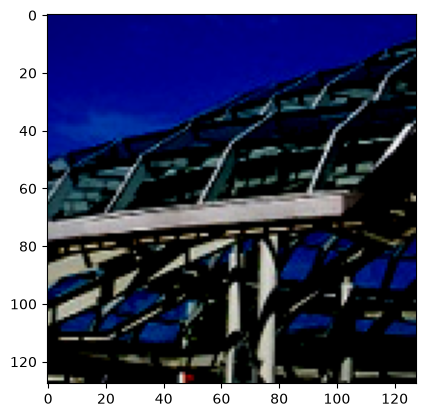

In [11]:
import matplotlib.pyplot as plt 
import numpy as np
for image,labels in train_data_loader:
    print(image.shape,labels.shape)
    img = image[0].numpy()
    print(img.shape)
    label = labels[0].item()
    print(train_image_data.class_names[label])
    img = np.transpose(img,(1,2,0))
    print(img.shape)
    print(label)
    plt.imshow(img)
    break

### Convolution Neural Network

In [12]:
import torch.nn as nn
import torch.optim as optim


In [32]:
class ImageClassifier(nn.Module):
    def __init__(self,input_dim,num_class):
        super(ImageClassifier,self).__init__()
        self.input_dim = input_dim
        self.num_class = num_class
        self.conv_layers= nn.Sequential(
            nn.Conv2d(3,32,kernel_size=3,stride=1,padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,stride=2),

            nn.Conv2d(32,64,kernel_size=3,stride=1,padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,stride=2),

            nn.Conv2d(64,128,kernel_size=3,stride=1,padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,stride=2),

            nn.Conv2d(128,256,kernel_size=3,stride=1,padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2,stride=2),
        )
        self.to_linear = None
        
        self._get_conv_output(self.input_dim)
        self.linear_layers = nn.Sequential(
            nn.Linear(self.to_linear,512),
            nn.ReLU(),
            nn.Linear(512,128),
            nn.ReLU(),
            nn.Linear(128,self.num_class)
        )
    def _get_conv_output(self,input_dim=128):
        with torch.no_grad():
            tensor = torch.zeros(1,3,input_dim,input_dim)
            output = self.conv_layers(tensor)
            
            self.to_linear =output.view(1,-1).size(1)

    def forward(self,x):
        x=self.conv_layers(x)
        x= x.view(x.size(0),-1)
        x=self.linear_layers(x)
        return x

In [34]:
device = 'cuda' if torch.cuda.is_available else 'cpu'
model = ImageClassifier(input_dim=128,num_class=6).to(device)
model

ImageClassifier(
  (conv_layers): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_st

In [36]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(),lr= 0.001)

In [39]:
epochs = 10
for epoch in range(epochs):
    model.train()
    running_loss=0.0
    for images,labels in train_data_loader:
        images = images.to(device)
        labels = labels.to(device)
        optimizer.zero_grad()
        outputs=model(images)
        loss = criterion(outputs,labels)
        loss.backward()
        optimizer.step()
        running_loss+=loss.item()
    print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(train_data_loader)}")

Epoch 1/10, Loss: 0.6103405830257302
Epoch 2/10, Loss: 0.5089657971962166
Epoch 3/10, Loss: 0.4420033918697905
Epoch 4/10, Loss: 0.3903595104745689
Epoch 5/10, Loss: 0.3647851254069724
Epoch 6/10, Loss: 0.327215150456901
Epoch 7/10, Loss: 0.2946395869101642
Epoch 8/10, Loss: 0.2657498536050184
Epoch 9/10, Loss: 0.237234762799767
Epoch 10/10, Loss: 0.21016423261654404


In [40]:
torch.save(model.state_dict(),'cnn_model.pth')

In [41]:
model.eval()
correct,total =0,0
with  torch.no_grad():
    for images,labels in test_data_loader:
        images,labels = images.to(device),labels.to(device)
        outputs = model(images)
        _,predicted = torch.max(outputs,1)
        total +=labels.size(0)
        correct += (predicted == labels).sum().item()

    print(f"Test accuracy = {100*correct/total:.2f}%") 

Test accuracy = 85.10%
